# analyze_rand.py

*Generated from `analyze_rand.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
analyze_rand.py - yields from the random-orientation SIM runs.

Reads rand_<MAT>_<tag><s>_<E>eV.dat (step 2) and rand_<MAT>_surfaces.dat (step 1):
  per surface  impacts, sputtered W (and C), yields, He reflection, fraction of
               impacts whose He reached the fixed shell
  per set      mean yield over surfaces +- SEM as in Jussila et al. 2018
               (SD_pop / sqrt(N)), plus the 'clean' mean without fixed-shell hits
Sputtered = cap + end + lost (see the deck header).

Outputs (--out): rand_<MAT>_<E>eV_per_surface.csv, rand_<MAT>_summary.csv (one row
per set and energy), rand_<MAT>_<E>eV_ipf.png (yield on the inverse pole figure).

    python analyze_rand.py --mat W  --dir runs_W
    python analyze_rand.py --mat WC --dir runs_WC
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'analyze_rand.py'
NB_RUN = "."          # folder with rand_W_*eV.dat and rand_W_surfaces.dat
ARGS = ["--mat", "W", "--dir", NB_RUN, "--out", NB_RUN]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

The cells below are the script.  They need the run's dumps (and OVITO where it is imported), so they were not run when this notebook was built; the outputs further down come from a cluster run.

In [ ]:
import argparse
import glob
import math
import os
import re

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

In [ ]:
COLS = {
    "W": ["i", "s", "e", "ang", "phi", "xt", "yt", "nW_cap", "nW_end", "nW_lost", "KE_W_cap",
          "fate", "hit_fixed", "t_end"],
    "WC": ["i", "s", "e", "ang", "phi", "xt", "yt", "nW_cap", "nC_cap", "nW_end", "nC_end",
           "nW_lost", "nC_lost", "KE_W_cap", "KE_C_cap", "fate", "hit_fixed", "t_end"],
}
SURF_COLS = {
    "W": ["tag", "s", "alpha", "beta", "gamma", "nx", "ny", "nz", "ox", "oy", "oz", "nW", "zs"],
    "WC": ["tag", "s", "alpha", "beta", "gamma", "nx", "ny", "nz", "ox", "oy", "oz", "nW", "nC", "zs",
           "topW", "topC", "fC_top"],
}


def ipf_cubic(n):
    v = np.sort(np.abs(n))
    return v[0] / (1 + v[2]), v[1] / (1 + v[2])


def ipf_hex(n):
    th = math.acos(min(1.0, abs(n[2])))
    ph = math.degrees(math.atan2(n[1], n[0])) % 60.0
    if ph > 30.0:
        ph = 60.0 - ph
    r = math.tan(th / 2)
    return r * math.cos(math.radians(ph)), r * math.sin(math.radians(ph))


def load(mat, d):
    frames = []
    for f in glob.glob(os.path.join(d, "rand_%s_*_*eV.dat" % mat)):
        m = re.search(r"rand_%s_([A-Za-z]+?)(\d+)_(\d+)eV\.dat$" % mat, os.path.basename(f))
        if not m:
            continue
        x = pd.read_csv(f, sep=r"\s+", comment="#", header=None, names=COLS[mat])
        x["tag"] = m.group(1)
        frames.append(x)
    if not frames:
        raise SystemExit("no rand_%s_*.dat files in %s" % (mat, d))
    df = pd.concat(frames, ignore_index=True)
    df["W_spt"] = df["nW_cap"] + df["nW_end"] + df["nW_lost"]
    if mat == "WC":
        df["C_spt"] = df["nC_cap"] + df["nC_end"] + df["nC_lost"]
    return df


def per_surface(df, mat):
    g = df.groupby(["tag", "s", "e"])
    out = g.agg(impacts=("i", "count"), W=("W_spt", "sum"), refl=("fate", lambda v: np.mean(v == 1)),
                frac_hit_fixed=("hit_fixed", "mean")).reset_index()
    out["Y_W"] = out["W"] / out["impacts"]
    clean = df[df["hit_fixed"] == 0].groupby(["tag", "s", "e"])
    out = out.merge(clean.agg(imp_clean=("i", "count"), W_clean=("W_spt", "sum")).reset_index(),
                    on=["tag", "s", "e"], how="left")
    out["Y_W_clean"] = out["W_clean"] / out["imp_clean"]
    if mat == "WC":
        c = g.agg(C=("C_spt", "sum")).reset_index()
        out = out.merge(c, on=["tag", "s", "e"])
        out["Y_C"] = out["C"] / out["impacts"]
        cc = clean.agg(C_clean=("C_spt", "sum")).reset_index()
        out = out.merge(cc, on=["tag", "s", "e"], how="left")
        out["Y_C_clean"] = out["C_clean"] / out["imp_clean"]
    return out


def sem_jussila(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return np.sqrt(np.mean((x - x.mean()) ** 2)) / math.sqrt(len(x)) if len(x) else float("nan")


def summary(ps, mat):
    rows = []
    for (tag, e), g in ps.groupby(["tag", "e"]):
        r = dict(set="random" if tag == "r" else tag, e=e, surfaces=len(g), impacts=int(g["impacts"].sum()),
                 Y_W=g["Y_W"].mean(), Y_W_SEM=sem_jussila(g["Y_W"]),
                 Y_W_clean=g["Y_W_clean"].mean(), refl=g["refl"].mean(),
                 hit_fixed=g["frac_hit_fixed"].mean())
        if mat == "WC":
            r.update(Y_C=g["Y_C"].mean(), Y_C_SEM=sem_jussila(g["Y_C"]), Y_C_clean=g["Y_C_clean"].mean())
        rows.append(r)
    return pd.DataFrame(rows)


def ipf_plot(ps, surf, mat, e, out):
    rnd = ps[(ps["tag"] == "r") & (ps["e"] == e)].merge(surf[surf["tag"] == "r"], on="s", how="inner")
    if rnd.empty:
        return
    key = "Y_C" if mat == "WC" else "Y_W"
    pts = np.array([(ipf_hex if mat == "WC" else ipf_cubic)(np.array([a, b, c]))
                    for a, b, c in rnd[["nx", "ny", "nz"]].values])
    fig, ax = plt.subplots(figsize=(6.4, 4.8))
    if mat == "WC":
        t = np.radians(np.linspace(0, 30, 100))
        ax.plot([0, 1], [0, 0], "k-", lw=1); ax.plot([0, math.cos(math.radians(30))], [0, 0.5], "k-", lw=1)
        ax.plot(np.cos(t), np.sin(t), "k-", lw=1)
        for lab, (x, y) in (("(0001)", (0, 0)), ("(11-20)", (1, 0)), ("(10-10)", (0.866, 0.5))):
            ax.text(x, y + 0.03, lab, fontsize=10, ha="center")
    else:
        u = np.linspace(0, 1, 100)
        arc = np.array([ipf_cubic(np.array([v, 1, 1]) / np.linalg.norm([v, 1, 1])) for v in u])
        ax.plot([0, 0], [0, math.sqrt(2) - 1], "k-", lw=1); ax.plot([0, 0.366], [0, 0.366], "k-", lw=1)
        ax.plot(arc[:, 0], arc[:, 1], "k-", lw=1)
        for lab, (x, y) in (("(001)", (0, 0)), ("(011)", (0, 0.414)), ("(111)", (0.366, 0.366))):
            ax.text(x, y + 0.012, lab, fontsize=10)
    sc = ax.scatter(pts[:, 0], pts[:, 1], c=rnd[key], s=60, cmap="viridis", edgecolors="k", linewidths=0.4)
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label("%s yield (atoms/He), %g eV" % ("C" if mat == "WC" else "W", e))
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("%s random surfaces: yield vs surface normal" % mat, fontsize=12)
    fig.tight_layout()
    p = os.path.join(out, "rand_%s_%geV_ipf.png" % (mat, e))
    fig.savefig(p, dpi=200)
    plt.close(fig)
    print("wrote", p)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--mat", choices=["W", "WC"], required=True)
    ap.add_argument("--dir", default=".")
    ap.add_argument("--out", default=".")
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    df = load(a.mat, a.dir)
    ps = per_surface(df, a.mat)
    for e, g in ps.groupby("e"):
        g.to_csv(os.path.join(a.out, "rand_%s_%geV_per_surface.csv" % (a.mat, e)), index=False)
    sm = summary(ps, a.mat)
    sm.to_csv(os.path.join(a.out, "rand_%s_summary.csv" % a.mat), index=False)
    with pd.option_context("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.4g}".format):
        print(sm.to_string(index=False))
    sf = os.path.join(a.dir, "rand_%s_surfaces.dat" % a.mat)
    if os.path.isfile(sf):
        surf = pd.read_csv(sf, sep=r"\s+", header=None, names=SURF_COLS[a.mat])
        surf = surf.drop_duplicates(subset=["tag", "s"], keep="last")
        for e in sorted(ps["e"].unique()):
            ipf_plot(ps, surf, a.mat, e, a.out)

In [ ]:
if __name__ == "__main__":
    main()

## Outputs

Example output: yield of each random W surface on the inverse pole figure, 300 and 500 eV.

In [2]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


rand_W_300eV_ipf.png


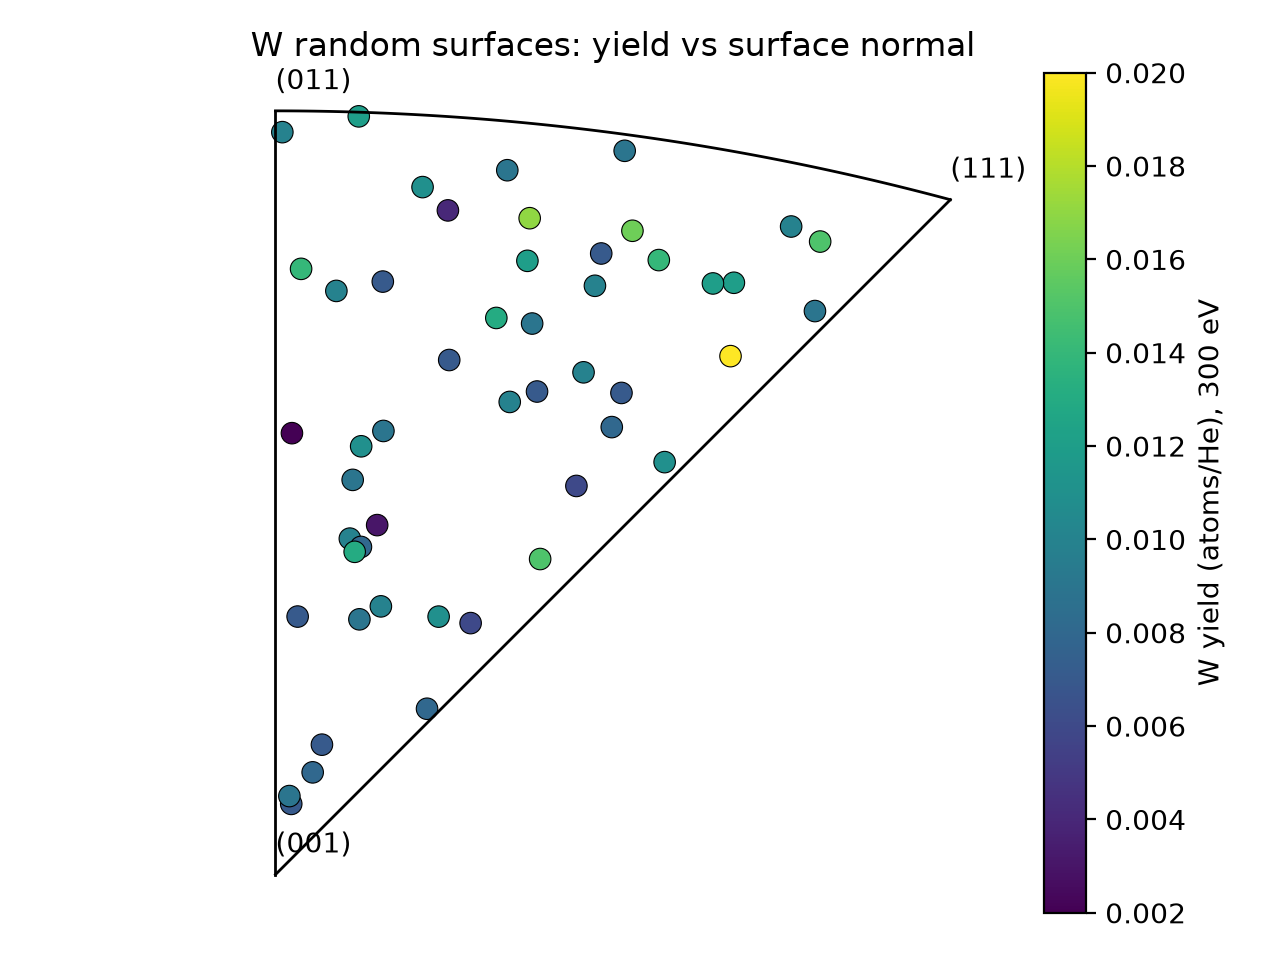

rand_W_500eV_ipf.png


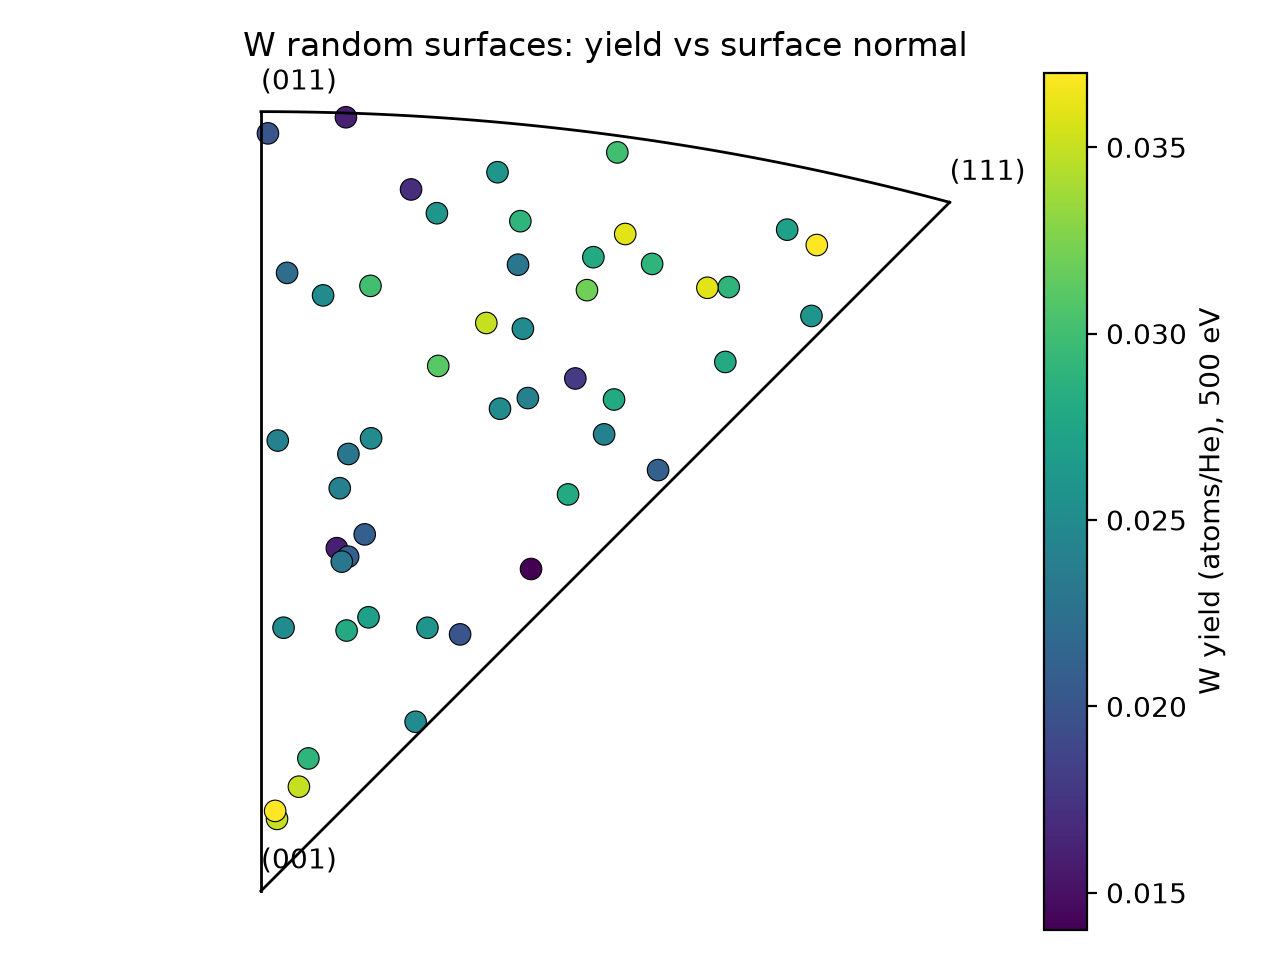

In [3]:
show(NB_RUN, ['rand_W_300eV_ipf.png', 'rand_W_500eV_ipf.png'])